In [ ]:
###
# 
# Author: Samuel BERLEMONT, Naji NAJARI
# Software description: Robust Autoencoders for Unsupervised Anomaly Detection
###


import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
plt.rcParams['axes.grid'] = False

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn import preprocessing
from sklearn.metrics import precision_score, recall_score, f1_score, roc_curve, auc, precision_recall_curve, average_precision_score
import random

from scipy import stats
from scipy.stats import iqr
import time
import sys
from RADON import  RADON, fit

## Selecting the GPU

In [6]:
#Check if GPU is available and select the available device
print(torch.cuda.is_available())
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

True


# Import the dataset

In [5]:
X_train = pd.read_csv('../data/X_train')
Y_train = pd.read_csv('../data/Y_train')
X_validation = pd.read_csv('../data/X_validation')
Y_validation = pd.read_csv('../data/Y_validation')
X_test = pd.read_csv('../data/X_test')
Y_test = pd.read_csv('../data/Y_test')

FileNotFoundError: [Errno 2] No such file or directory: '../data/X_train'

In [4]:
X_train

,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
0,0.000000,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,0.000000,3.043558e-08,0.000018,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,0.000000,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.000000,2.087011e-07,0.000040,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.000000,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74072,0.000000,2.391367e-08,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
74073,0.000000,1.463806e-07,0.000298,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
74074,0.000000,2.971092e-07,0.001446,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
74075,0.000165,7.391498e-08,0.000205,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


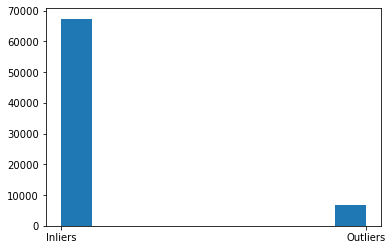

In [5]:
# The percentage of training data contamination 
X_label = (1 * (Y_train!='normal').values).reshape(-1)
plt.hist(X_label)
plt.xticks([0,1],["Inliers","Outliers"])
plt.show()

# Data preprocessing

## 1. Min-Max normalization

In [6]:
min_max_scaler = preprocessing.MinMaxScaler() 

X_train = pd.DataFrame(min_max_scaler.fit_transform(X_train),columns=X_train.columns)
X_validation = pd.DataFrame(min_max_scaler.fit_transform(X_validation),columns=X_validation.columns)
X_test = pd.DataFrame(min_max_scaler.fit_transform(X_test),columns=X_test.columns)


In [7]:
X_train.describe()

,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
count,74077.000000,7.407700e+04,74077.000000,74077.000000,74077.000000,74077.000000,74077.000000,74077.000000,74077.000000,74077.000000,...,74077.000000,74077.000000,74077.000000,74077.000000,74077.000000,74077.000000,74077.000000,74077.000000,74077.000000,74077.000000
mean,0.004518,2.277046e-05,0.000592,0.000121,0.001305,0.000045,0.002964,0.000327,0.649365,0.000062,...,0.049368,0.004860,0.000189,0.005440,0.059047,0.004873,0.001647,0.000634,0.873321,0.000391
std,0.038698,3.685747e-03,0.010030,0.011022,0.035004,0.005477,0.029776,0.011937,0.477172,0.004174,...,0.216636,0.069543,0.013746,0.073558,0.235714,0.069639,0.040549,0.025181,0.332615,0.019782
min,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,3.260955e-08,0.000006,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
50%,0.000000,1.623231e-07,0.000047,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,0.000000,2.304408e-07,0.000250,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,1.000000,1.000000e+00,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## 2. Create batches 

In [8]:
# Prepare data for AE (split data in batches) 
batch_size = 256
train_loader = torch.utils.data.DataLoader(torch.FloatTensor(X_train.values).to(device), batch_size=batch_size)

validation_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(torch.FloatTensor(X_validation.values).to(device),\
                                                torch.FloatTensor(Y_validation.values!='normal').to(device)), batch_size=batch_size)
  
test_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(torch.FloatTensor(X_test.values).to(device),\
                                                torch.FloatTensor(Y_test.values!='normal').to(device)), batch_size=batch_size)

# RADON training 

## 1. Hyperparameters 

In [9]:
# default hyperparameters 

repetitions = 1   # Repeat the experiments n times to study the sensitivity regarding the initialization (randomness)
epochs = 100
projection_after_epochs = 20 
batch_size = 256


#RADON default hyperparamters 
bin_estimator = "knuth"
lr = 0.001

#Dimensions of RADON latent layers 
input_dim = 122
dim1 = 32
dim2 = 8

## 2. Import and train  RADON 

Repetition : 0
 Epoch :  1 , Train cost :  10490.772026788443
 Epoch :  2 , Train cost :  965.1113297822885
 Epoch :  3 , Train cost :  403.2801671791822
 Epoch :  4 , Train cost :  298.51196057582274
 Epoch :  5 , Train cost :  231.2125917696394
 Epoch :  6 , Train cost :  179.77745143556967
 Epoch :  7 , Train cost :  150.344711571699
 Epoch :  8 , Train cost :  119.25141923630144
 Epoch :  9 , Train cost :  99.26830337930005
 Epoch :  10 , Train cost :  87.72410576452967
 Epoch :  11 , Train cost :  74.8875942187151
 Epoch :  12 , Train cost :  70.06725213199388
 Epoch :  13 , Train cost :  66.34710009815171
 Epoch :  14 , Train cost :  63.211873434484005
 Epoch :  15 , Train cost :  60.61348930990789
 Epoch :  16 , Train cost :  58.45749111415353
 Epoch :  17 , Train cost :  56.44982621225063
 Epoch :  18 , Train cost :  54.59837583935587
 Epoch :  19 , Train cost :  52.90403720823815
threshold_L 0.9836726188659668
threshold_S 0.9836726188659668


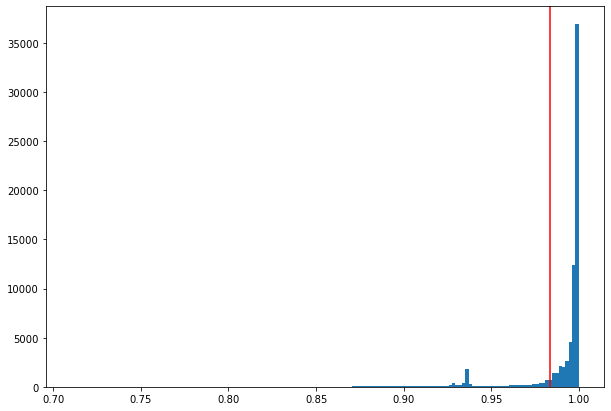

 Epoch :  20 , Train cost :  51.397250948881265
 Epoch :  21 , Train cost :  6990.716760881245
 Epoch :  22 , Train cost :  4967.667573522776
 Epoch :  23 , Train cost :  4356.013234436512
 Epoch :  24 , Train cost :  3236.5139756398275
 Epoch :  25 , Train cost :  3132.0177918942645
 Epoch :  26 , Train cost :  2590.8499651625752
 Epoch :  27 , Train cost :  2550.7862198464572
 Epoch :  28 , Train cost :  2349.867473734077
 Epoch :  29 , Train cost :  2249.6963919918053
 Epoch :  30 , Train cost :  2156.7852572379634
 Epoch :  31 , Train cost :  2058.7301795370877
 Epoch :  32 , Train cost :  1997.4621657743119
 Epoch :  33 , Train cost :  1939.011742027942
 Epoch :  34 , Train cost :  1875.7636041818187
 Epoch :  35 , Train cost :  1822.360701891128
 Epoch :  36 , Train cost :  1780.651664685458
 Epoch :  37 , Train cost :  1757.6879618619569
 Epoch :  38 , Train cost :  1736.1669988175854
 Epoch :  39 , Train cost :  1700.6870983135886
threshold_L 0.9815957546234131
threshold_S 0.03

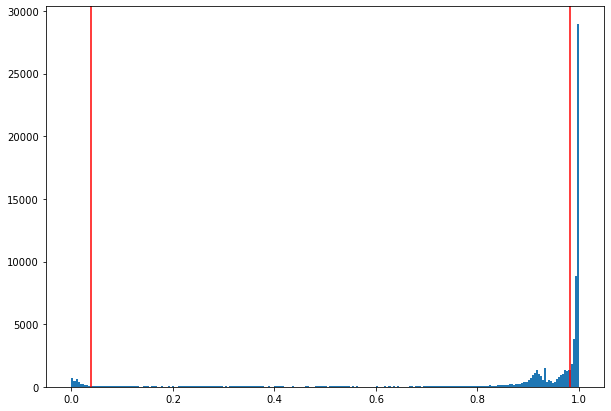

 Epoch :  40 , Train cost :  1687.5673110312782
 Epoch :  41 , Train cost :  1.5860203527809063
 Epoch :  42 , Train cost :  1.106090891375061
 Epoch :  43 , Train cost :  1.0009193197729473
 Epoch :  44 , Train cost :  0.9307249036555731
 Epoch :  45 , Train cost :  0.8782415397618024
 Epoch :  46 , Train cost :  0.8365100922492275
 Epoch :  47 , Train cost :  0.8018698796677199
 Epoch :  48 , Train cost :  0.7721610585704184
 Epoch :  49 , Train cost :  0.7459847176924086
 Epoch :  50 , Train cost :  0.7224246930582012
 Epoch :  51 , Train cost :  0.7008311236668305
 Epoch :  52 , Train cost :  0.6807209043799958
 Epoch :  53 , Train cost :  0.6617820321334875
 Epoch :  54 , Train cost :  0.6437668470962308
 Epoch :  55 , Train cost :  0.6264594873646274
 Epoch :  56 , Train cost :  0.6097012137788624
 Epoch :  57 , Train cost :  0.5934816544431669
 Epoch :  58 , Train cost :  0.5777119068388856
 Epoch :  59 , Train cost :  0.5623296190497058
threshold_L 0.9819352626800537
threshold_

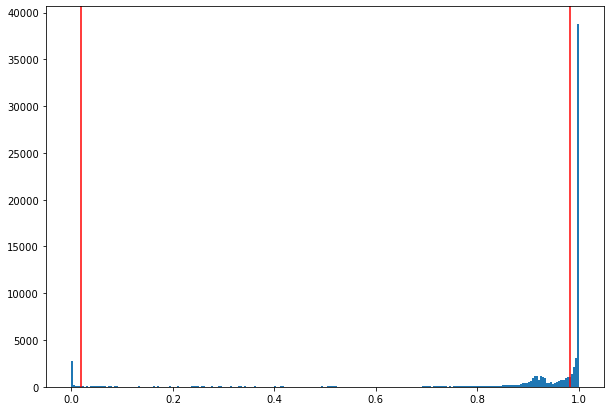

 Epoch :  60 , Train cost :  0.5471955157181583
 Epoch :  61 , Train cost :  0.7881138613247458
 Epoch :  62 , Train cost :  0.7218549081680976
 Epoch :  63 , Train cost :  0.6831695748924176
 Epoch :  64 , Train cost :  0.6508300546511236
 Epoch :  65 , Train cost :  0.6217176721747819
 Epoch :  66 , Train cost :  0.5944834646688832
 Epoch :  67 , Train cost :  0.5675903880000988
 Epoch :  68 , Train cost :  0.5394785754942859
 Epoch :  69 , Train cost :  0.5150616838191127
 Epoch :  70 , Train cost :  0.49359846831157483
 Epoch :  71 , Train cost :  0.4729391727082657
 Epoch :  72 , Train cost :  0.45272223439496884
 Epoch :  73 , Train cost :  0.4328200124473369
 Epoch :  74 , Train cost :  0.41351745546080565
 Epoch :  75 , Train cost :  0.3958475386502869
 Epoch :  76 , Train cost :  0.38037947131715555
 Epoch :  77 , Train cost :  0.36653241892645383
 Epoch :  78 , Train cost :  0.3535686982313564
 Epoch :  79 , Train cost :  0.34099033725260597
threshold_L 0.989921510219574
thre

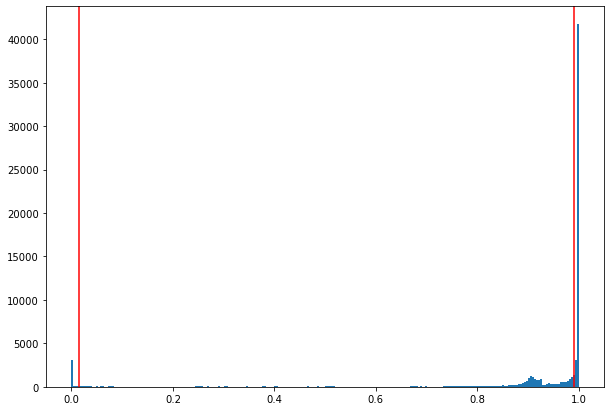

 Epoch :  80 , Train cost :  0.32864376693532904
 Epoch :  81 , Train cost :  0.23910411240922258
 Epoch :  82 , Train cost :  0.2196011151327184
 Epoch :  83 , Train cost :  0.2082059966774068
 Epoch :  84 , Train cost :  0.19907284480314047
 Epoch :  85 , Train cost :  0.19127005303516853
 Epoch :  86 , Train cost :  0.18437969864362458
 Epoch :  87 , Train cost :  0.17820905044982283
 Epoch :  88 , Train cost :  0.17258420634061622
 Epoch :  89 , Train cost :  0.16738362019941633
 Epoch :  90 , Train cost :  0.16258009963075892
 Epoch :  91 , Train cost :  0.1581414390639111
 Epoch :  92 , Train cost :  0.1538938201883866
 Epoch :  93 , Train cost :  0.1497801613527372
 Epoch :  94 , Train cost :  0.14573193275100493
 Epoch :  95 , Train cost :  0.14161417016816813
 Epoch :  96 , Train cost :  0.13724906035145068
 Epoch :  97 , Train cost :  0.13266089871581244
 Epoch :  98 , Train cost :  0.1284171286486071
 Epoch :  99 , Train cost :  0.12481167486635059
threshold_L 0.985941350460

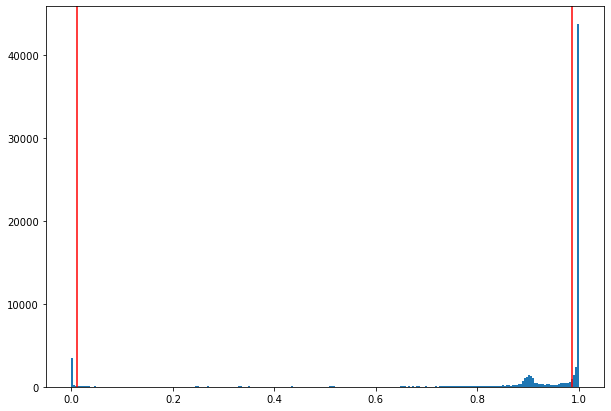

 Epoch :  100 , Train cost :  0.12139493433164716


In [10]:
train_time = [[] for i in range(repetitions)]
model = [[] for i in range(repetitions)]
loss= [[] for i in range(repetitions)]

th= [[] for i in range(repetitions)]
th_L= [[] for i in range(repetitions)]
th_S= [[] for i in range(repetitions)]




for i in range(repetitions):

    print('Repetition : {}'.format(i))
    
    start_time=time.time()
    model[i]= RADON(input_dim, dim1, dim2 ).train()
    loss[i],  th[i], th_L[i],th_S[i] = fit(model[i], X_train, bin_estimator , epochs, \
                                           projection_after_epochs, batch_size, lr,  verbose = False)
    end_time=time.time()
    train_time[i]=(end_time-start_time)
    torch.save(model[i].state_dict(), f'./Trained_models/RADON_BinEstimator={bin_estimator}_repetition={i}.pth')


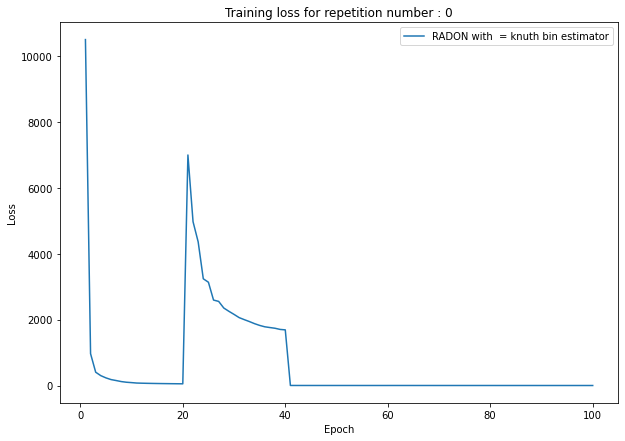

In [11]:
for rep in range(repetitions):

    ax = np.arange(1,len(loss[rep])+1)
    plt.figure(figsize=(10,7))
    plt.plot(ax,loss[rep],label='RADON with  = {} bin estimator'.format(bin_estimator))
    plt.title('Training loss for repetition number : {}'.format(rep))
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend()
    plt.show()

# RADON Test 

## 1. Test samples reconstruction error

In [12]:
criterion = nn.CosineSimilarity(dim=1, eps=1e-5)


In [13]:
y = [[]for rep in range(repetitions)]
test_loss = [[]for rep in range(repetitions)]
z = [[]for rep in range(repetitions)]


for rep in range(repetitions):
    model[rep].eval()
    with torch.no_grad():
        for i, (data, label) in enumerate(test_loader):

            data = data.reshape(-1,122).to(device)
            recon_batch = model[rep](data)

            test_loss[rep].extend((1-criterion(recon_batch, data)).cpu().numpy())
            y[rep].extend(label.cpu().numpy())

    y[rep] = np.array(y[rep]).reshape(-1)
    test_loss[rep] = np.array(test_loss[rep])


-----------------Repetition : 0 ------------------------


/home/dm/anaconda3/envs/radon/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1376: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  X = np.atleast_1d(X.T if isinstance(X, np.ndarray) else np.asarray(X))


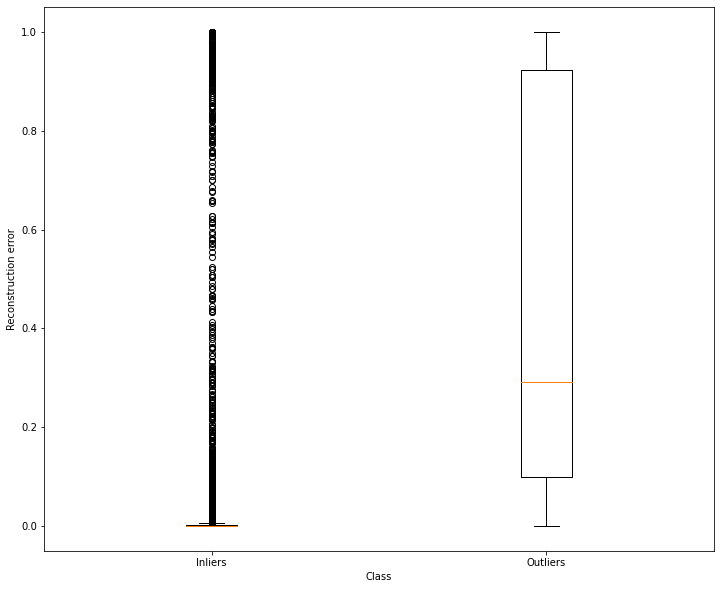

In [14]:
for rep in range(repetitions):
    print('-----------------Repetition : {} ------------------------'.format(rep))
    plt.figure(figsize=(12,10))
    bx = []
    for i in range(2):
            bx.append(test_loss[rep][np.where(y[rep]==i)])
    plt.boxplot(bx,positions=np.arange(2))
    plt.ylabel('Reconstruction error')
    plt.xticks([0,1],['Inliers','Outliers'])
    plt.xlabel('Class')
    plt.show()

## 2. Test AUROC (Area Under the Receiver Operating Characteristic Curve)

-----------------Repetition : 0 ------------------------


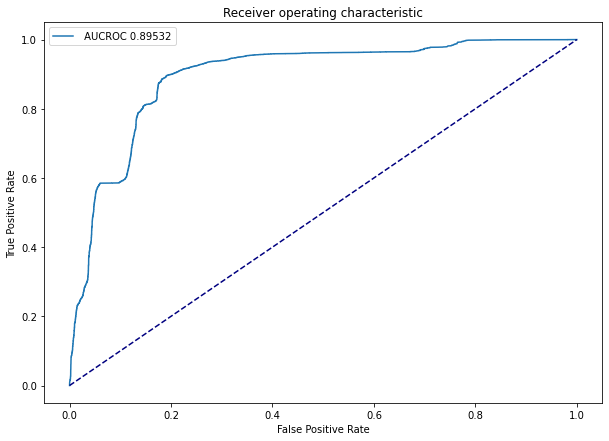

In [15]:
aucroc = []
for rep in range(repetitions):
    print('-----------------Repetition : {} ------------------------'.format(rep))

    fpr, tpr, thresholds = roc_curve(y[rep] != 0, test_loss[rep],pos_label=1)
    roc_auc= auc(fpr , tpr )
    aucroc.append(roc_auc)
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold= thresholds[optimal_idx]

    plt.figure(figsize=(10,7))
    plt.plot(fpr, tpr, label=' AUCROC {:.5f}'
             .format(roc_auc))
    plt.plot([0, 1], [0, 1], color='navy',  linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver operating characteristic')
    plt.legend()
    plt.show()

## 3. Test AUPRC (Area Under the Precision Recall Curve)

-----------------Repetition : 0 ------------------------


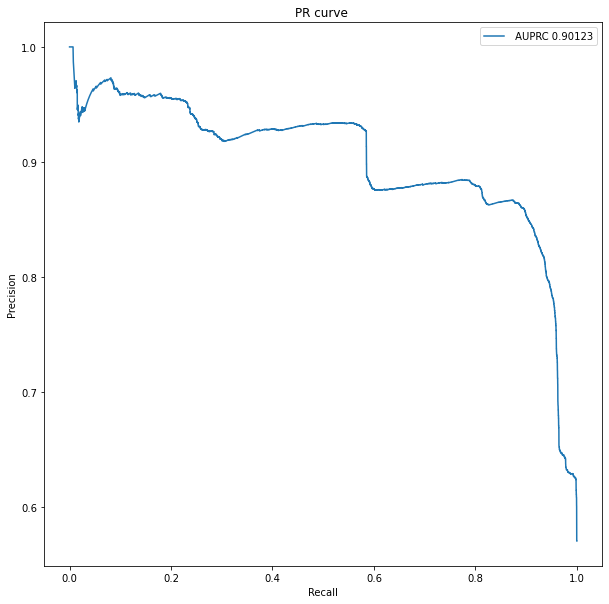

In [16]:
aucpr = []

for rep in range(repetitions):
    print('-----------------Repetition : {} ------------------------'.format(rep))
    pr, rc, thresholds = precision_recall_curve(y[rep] != 0, test_loss[rep],pos_label=1)

    pr_auc = auc(rc , pr )
    aucpr.append(pr_auc)
    optimal_idx = np.argmax(rc + pr)
    optimal_threshold_pr = thresholds[optimal_idx]
    plt.figure(figsize=(10,10))

    plt.plot(rc,pr, label=' AUPRC {:.5f}'
             .format(pr_auc))
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('PR curve ')
    plt.legend()

    plt.show()